# Phase 3 — Feature Engineering & Data Splitting

**Objective:** Prepare the cleaned crop recommendation dataset for machine learning by encoding the target variable, scaling numerical features, and splitting into train/test sets with stratification.

**Inputs:** `Crop_recommendation_cleaned.csv` (from Phase 2) or `Crop_recommendation.csv` (raw fallback)  
**Outputs:** `X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv`, `preprocessing_pipeline.joblib`

## 1. Setup & Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.pipeline import Pipeline

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='husl', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#f8f9fa',
    'axes.facecolor': '#ffffff',
    'axes.edgecolor': '#dee2e6',
    'grid.color': '#e9ecef',
    'font.family': 'sans-serif',
})

print('\u2705 Libraries imported successfully.')

✅ Libraries imported successfully.


## 2. Load Cleaned Dataset

In [2]:
# Load dataset — prefer cleaned version from Phase 2, fallback to raw
cleaned_path = 'Crop_recommendation_cleaned.csv'
raw_path = 'Crop_recommendation.csv'

if os.path.exists(cleaned_path):
    df = pd.read_csv(cleaned_path)
    print(f'\u2705 Loaded cleaned dataset: {cleaned_path}')
else:
    df = pd.read_csv(raw_path)
    df = df.drop_duplicates(keep='first').reset_index(drop=True)
    print(f'\u26a0\ufe0f  Cleaned file not found. Loaded raw dataset and removed duplicates.')

print(f'   Shape: {df.shape[0]} rows \u00d7 {df.shape[1]} columns')
print(f'   Columns: {list(df.columns)}')
print(f'   Unique crops: {df["label"].nunique()}')
df.head()

⚠️  Cleaned file not found. Loaded raw dataset and removed duplicates.
   Shape: 2200 rows × 8 columns
   Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
   Unique crops: 22


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 3. Feature–Target Separation

Split the dataframe into feature matrix **X** (7 numerical columns) and target vector **y** (crop label).

In [3]:
# Separate features and target
feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

X = df[feature_cols].copy()
y = df['label'].copy()

print(f'Feature matrix X: {X.shape}')
print(f'Target vector y:  {y.shape}')
print(f'\nFeature dtypes:\n{X.dtypes}')
print(f'\nTarget dtype: {y.dtype}')
print(f'Target classes ({y.nunique()}): {sorted(y.unique())}')

Feature matrix X: (2200, 7)
Target vector y:  (2200,)

Feature dtypes:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
dtype: object

Target dtype: str
Target classes (22): ['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']


## 4. Target Label Encoding

Machine learning algorithms require numerical targets. We use **LabelEncoder** to map each crop name to a unique integer (0–21).

> **Why LabelEncoder and not OneHotEncoding?**  
> The target variable is the output, not an input feature. Scikit-learn classifiers natively handle integer-encoded targets for multi-class classification. One-hot encoding the target is only needed for specific frameworks (e.g., Keras with `categorical_crossentropy`). For tree-based models, SVM, KNN, and Logistic Regression, integer labels are the standard.

In [4]:
# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Display the mapping
label_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))

print('=== Label Encoding Mapping ===')
print(f'{"Crop Name":>15}  \u2192  Encoded Value')
print('-' * 35)
for crop, code in sorted(label_mapping.items(), key=lambda x: x[1]):
    print(f'{crop:>15}  \u2192  {code}')

print(f'\n\u2705 Encoded {len(label_mapping)} crop classes (0 to {len(label_mapping)-1})')
print(f'   Encoded target shape: {y_encoded.shape}')

# Save mapping for later reference
label_map_df = pd.DataFrame(list(label_mapping.items()), columns=['crop_name', 'encoded_value'])
label_map_df.to_csv('label_encoding_map.csv', index=False)
print(f'   Mapping saved to: label_encoding_map.csv')

=== Label Encoding Mapping ===
      Crop Name  →  Encoded Value
-----------------------------------
          apple  →  0
         banana  →  1
      blackgram  →  2
       chickpea  →  3
        coconut  →  4
         coffee  →  5
         cotton  →  6
         grapes  →  7
           jute  →  8
    kidneybeans  →  9
         lentil  →  10
          maize  →  11
          mango  →  12
      mothbeans  →  13
       mungbean  →  14
      muskmelon  →  15
         orange  →  16
         papaya  →  17
     pigeonpeas  →  18
    pomegranate  →  19
           rice  →  20
     watermelon  →  21

✅ Encoded 22 crop classes (0 to 21)
   Encoded target shape: (2200,)
   Mapping saved to: label_encoding_map.csv


## 5. Feature Scaling — StandardScaler vs MinMaxScaler

### Why scaling matters
Features in this dataset operate on vastly different scales:
- **N, P, K:** 0–140 (soil nutrients)
- **Temperature:** 8–44°C
- **Humidity:** 14–99%
- **pH:** 3.5–10
- **Rainfall:** 20–300 mm

Distance-based algorithms (KNN, SVM) and gradient-based algorithms (Logistic Regression, Neural Networks) are **sensitive to feature scale**. Without scaling, features with large ranges (rainfall, humidity) dominate distance calculations.

### StandardScaler (chosen) vs MinMaxScaler

| Criterion | StandardScaler | MinMaxScaler |
|---|---|---|
| **Formula** | (x − μ) / σ | (x − min) / (max − min) |
| **Output range** | Centered at 0, no fixed bounds | Fixed [0, 1] |
| **Outlier sensitivity** | Less sensitive (uses std) | Highly sensitive (uses min/max) |
| **Best for** | Gaussian-like distributions | Bounded/uniform distributions |

**Decision: StandardScaler** is chosen because:
1. **Outlier resilience** — Phase 2 found legitimate outliers (e.g., extreme rainfall for rice). MinMaxScaler would compress the majority of values into a narrow band.
2. **Distribution compatibility** — Several features (temperature, pH) are roughly Gaussian. StandardScaler preserves this shape.
3. **Algorithm compatibility** — SVM, Logistic Regression, and KNN all perform optimally with zero-mean, unit-variance features.
4. **Common practice** — StandardScaler is the default recommendation for multi-class classification pipelines in scikit-learn.

We also compare both scalers visually below to validate our choice.

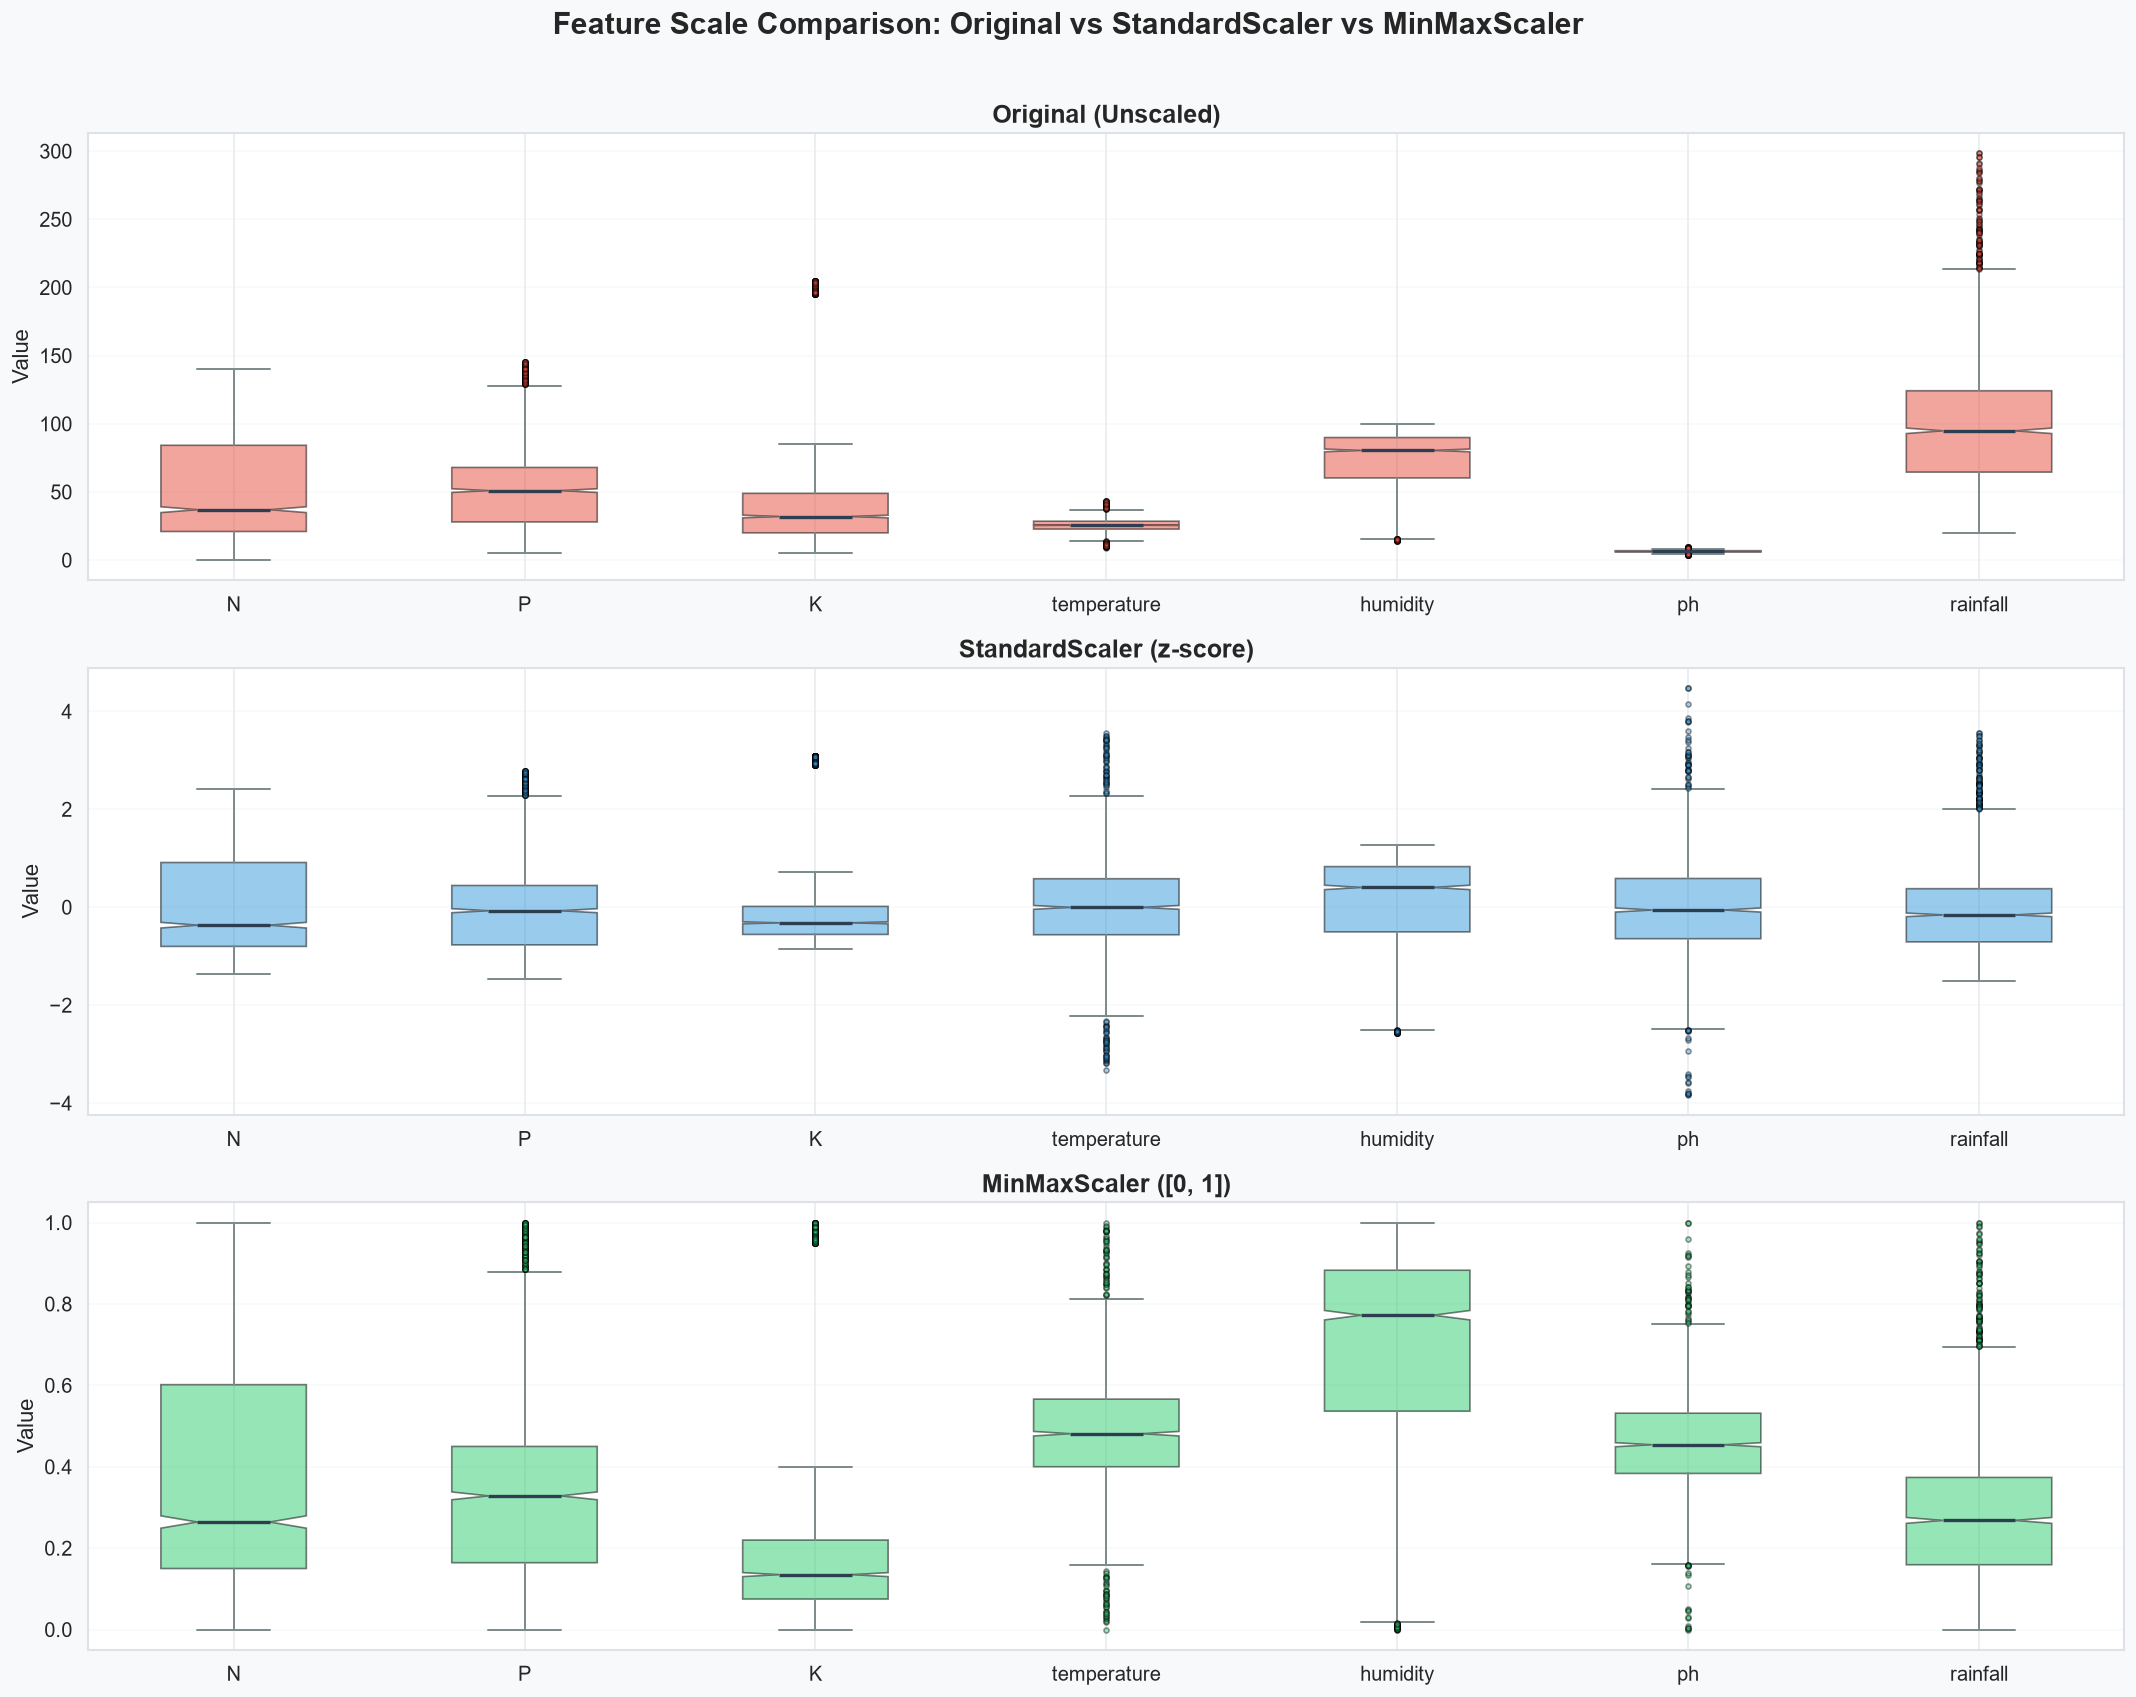

ℹ️  StandardScaler centers all features around 0 with comparable spread,
   while preserving the shape of each distribution (including outliers).
   MinMaxScaler compresses values into [0,1] but outliers skew the compression.


In [5]:
# Compare original, StandardScaler, and MinMaxScaler distributions
scaler_standard = StandardScaler()
scaler_minmax = MinMaxScaler()

X_standard = pd.DataFrame(scaler_standard.fit_transform(X), columns=feature_cols)
X_minmax = pd.DataFrame(scaler_minmax.fit_transform(X), columns=feature_cols)

fig, axes = plt.subplots(3, 1, figsize=(18, 14))

datasets = [
    (X, 'Original (Unscaled)', '#e74c3c'),
    (X_standard, 'StandardScaler (z-score)', '#3498db'),
    (X_minmax, 'MinMaxScaler ([0, 1])', '#2ecc71'),
]

for ax, (data, title, color) in zip(axes, datasets):
    bp = ax.boxplot([data[col] for col in feature_cols], 
                     tick_labels=feature_cols, patch_artist=True, notch=True,
                     boxprops=dict(facecolor=color, alpha=0.5),
                     medianprops=dict(color='#2c3e50', linewidth=2),
                     whiskerprops=dict(color='#7f8c8d', linewidth=1.2),
                     capprops=dict(color='#7f8c8d', linewidth=1.2),
                     flierprops=dict(marker='o', markerfacecolor=color, markersize=3, alpha=0.4))
    ax.set_title(title, fontsize=15, fontweight='bold')
    ax.set_ylabel('Value')
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Feature Scale Comparison: Original vs StandardScaler vs MinMaxScaler',
             fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('\u2139\ufe0f  StandardScaler centers all features around 0 with comparable spread,')
print('   while preserving the shape of each distribution (including outliers).')
print('   MinMaxScaler compresses values into [0,1] but outliers skew the compression.')

In [6]:
# Apply the chosen scaler (StandardScaler)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=feature_cols)

print('=== StandardScaler Applied ===')
print(f'\nScaled feature statistics:')
scaled_stats = X_scaled.describe().loc[['mean', 'std', 'min', 'max']].T
scaled_stats.columns = ['Mean', 'Std Dev', 'Min', 'Max']
print(scaled_stats.round(4).to_string())

print(f'\n\u2705 All features now have mean \u2248 0 and std \u2248 1')
print(f'   Scaled feature matrix shape: {X_scaled.shape}')

=== StandardScaler Applied ===

Scaled feature statistics:
             Mean  Std Dev     Min     Max
N            -0.0   1.0002 -1.3696  2.4235
P             0.0   1.0002 -1.4665  2.7787
K            -0.0   1.0002 -0.8521  3.0976
temperature   0.0   1.0002 -3.3166  3.5672
humidity     -0.0   1.0002 -2.5708  1.2804
ph           -0.0   1.0002 -3.8316  4.4789
rainfall      0.0   1.0002 -1.5152  3.5507

✅ All features now have mean ≈ 0 and std ≈ 1
   Scaled feature matrix shape: (2200, 7)


## 6. Train–Test Split (80/20 with Stratification)

### Split ratio justification

| Ratio | Pros | Cons |
|---|---|---|
| **80/20 (chosen)** | Enough training data for 22 classes; ~20 test samples per class for reliable per-class metrics | Standard and well-validated |
| 70/30 | More test data | Fewer training samples per class (~70), may hurt minority patterns |
| 90/10 | More training data | Only ~10 test samples per class — unreliable per-class accuracy |

**Decision: 80/20** because:
1. With ~2,200 samples and 22 classes, 80% training gives ~80 samples per class — sufficient for most classifiers.
2. 20% test gives ~20 samples per class — enough for meaningful per-class precision/recall.
3. **Stratification** ensures each crop has exactly the same proportion in train and test, preventing class imbalance from random splitting.

In [7]:
# Stratified train/test split
RANDOM_STATE = 42
TEST_SIZE = 0.20

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_encoded    # ensures proportional class distribution in both sets
)

print('=== Train/Test Split Summary ===')
print(f'  Split ratio:    {int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)} (train/test)')
print(f'  Random state:   {RANDOM_STATE}')
print(f'  Stratified:     Yes')
print(f'\n  X_train shape:  {X_train.shape}')
print(f'  X_test shape:   {X_test.shape}')
print(f'  y_train shape:  {y_train.shape}')
print(f'  y_test shape:   {y_test.shape}')
print(f'\n  Train samples:  {len(X_train)} ({len(X_train)/len(X_scaled)*100:.1f}%)')
print(f'  Test samples:   {len(X_test)} ({len(X_test)/len(X_scaled)*100:.1f}%)')

=== Train/Test Split Summary ===
  Split ratio:    80/20 (train/test)
  Random state:   42
  Stratified:     Yes

  X_train shape:  (1760, 7)
  X_test shape:   (440, 7)
  y_train shape:  (1760,)
  y_test shape:   (440,)

  Train samples:  1760 (80.0%)
  Test samples:   440 (20.0%)


### Verify Stratification

Confirm that the class proportions are preserved identically in both the training and test sets.

=== Stratification Verification ===
             Full Dataset  Train Set  Test Set  Train %  Test %
Crop                                                           
apple                 100         80        20     4.55    4.55
banana                100         80        20     4.55    4.55
blackgram             100         80        20     4.55    4.55
chickpea              100         80        20     4.55    4.55
coconut               100         80        20     4.55    4.55
coffee                100         80        20     4.55    4.55
cotton                100         80        20     4.55    4.55
grapes                100         80        20     4.55    4.55
jute                  100         80        20     4.55    4.55
kidneybeans           100         80        20     4.55    4.55
lentil                100         80        20     4.55    4.55
maize                 100         80        20     4.55    4.55
mango                 100         80        20     4.55    4.55
moth

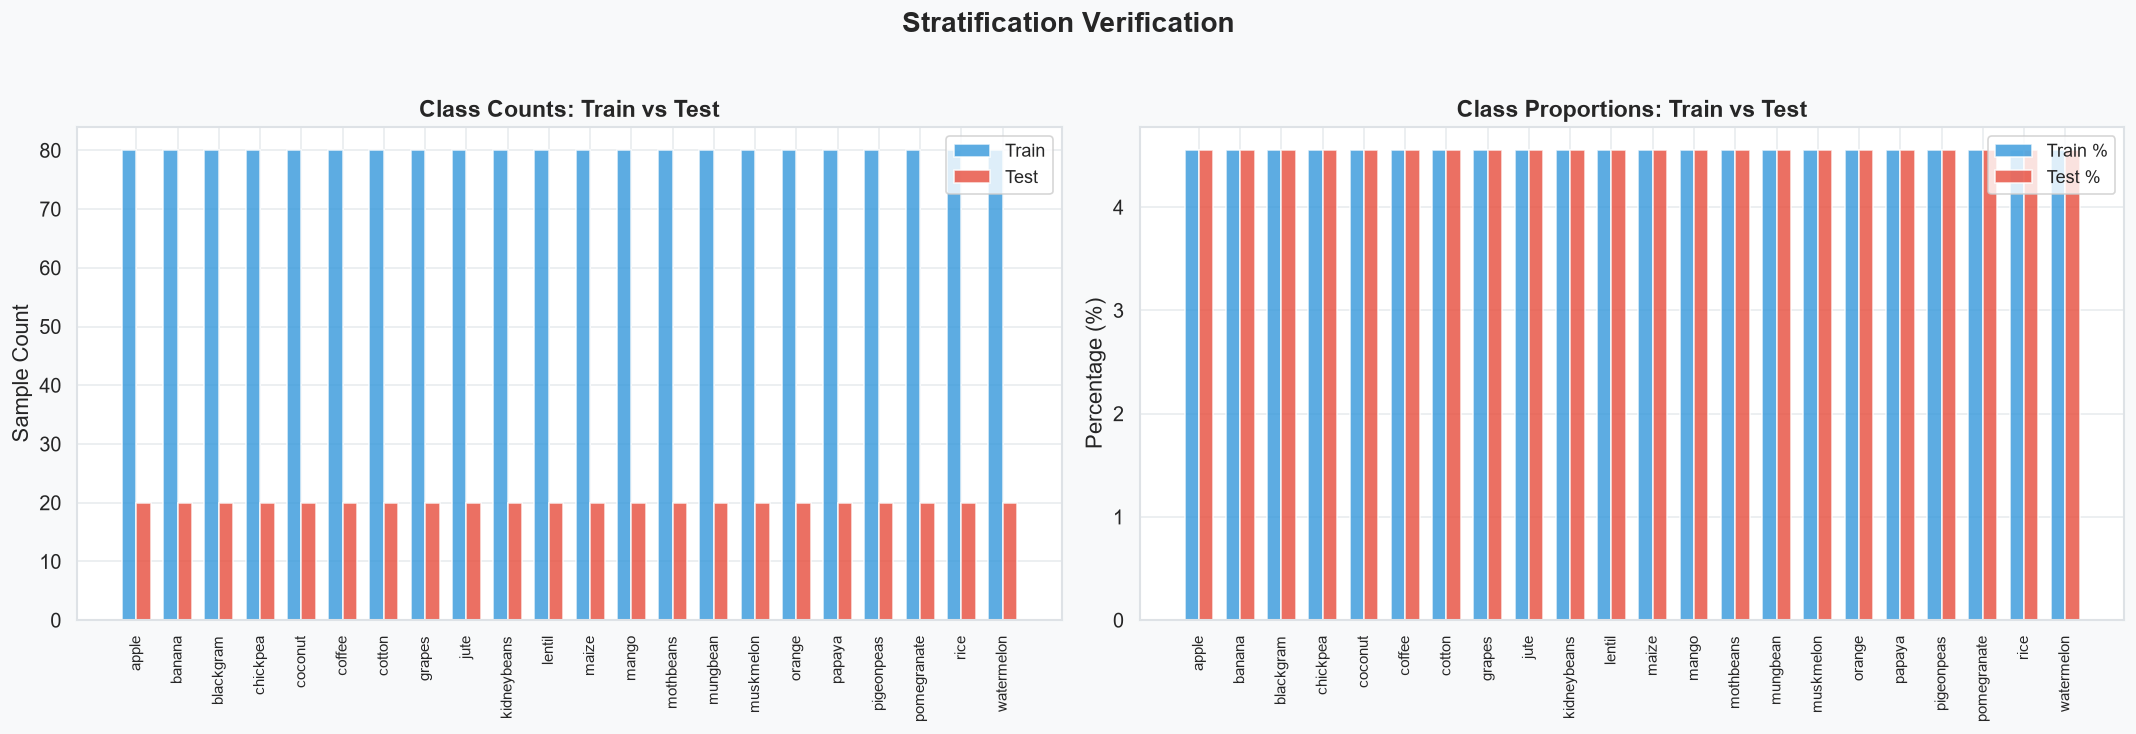


✅ Class proportions are identical in train and test sets — stratification confirmed.


In [8]:
# Verify stratification: compare class distributions
train_dist = pd.Series(y_train).value_counts().sort_index()
test_dist = pd.Series(y_test).value_counts().sort_index()
full_dist = pd.Series(y_encoded).value_counts().sort_index()

strat_df = pd.DataFrame({
    'Full Dataset': full_dist,
    'Train Set': train_dist,
    'Test Set': test_dist,
    'Train %': (train_dist / train_dist.sum() * 100).round(2),
    'Test %': (test_dist / test_dist.sum() * 100).round(2),
})
strat_df.index = [label_encoder.inverse_transform([i])[0] for i in strat_df.index]
strat_df.index.name = 'Crop'

print('=== Stratification Verification ===')
print(strat_df.to_string())

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

crops = strat_df.index
x_pos = np.arange(len(crops))
bar_width = 0.35

axes[0].bar(x_pos - bar_width/2, strat_df['Train Set'], bar_width, 
            label='Train', color='#3498db', edgecolor='white', alpha=0.8)
axes[0].bar(x_pos + bar_width/2, strat_df['Test Set'], bar_width, 
            label='Test', color='#e74c3c', edgecolor='white', alpha=0.8)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(crops, rotation=90, fontsize=9)
axes[0].set_ylabel('Sample Count')
axes[0].set_title('Class Counts: Train vs Test', fontweight='bold', fontsize=14)
axes[0].legend(fontsize=11)

axes[1].bar(x_pos - bar_width/2, strat_df['Train %'], bar_width, 
            label='Train %', color='#3498db', edgecolor='white', alpha=0.8)
axes[1].bar(x_pos + bar_width/2, strat_df['Test %'], bar_width, 
            label='Test %', color='#e74c3c', edgecolor='white', alpha=0.8)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(crops, rotation=90, fontsize=9)
axes[1].set_ylabel('Percentage (%)')
axes[1].set_title('Class Proportions: Train vs Test', fontweight='bold', fontsize=14)
axes[1].legend(fontsize=11)

plt.suptitle('Stratification Verification', fontsize=17, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\n\u2705 Class proportions are identical in train and test sets \u2014 stratification confirmed.')

## 7. Scaled Feature Distribution Comparison (Before vs After)

Visualize how scaling transformed each feature to confirm proper normalization.

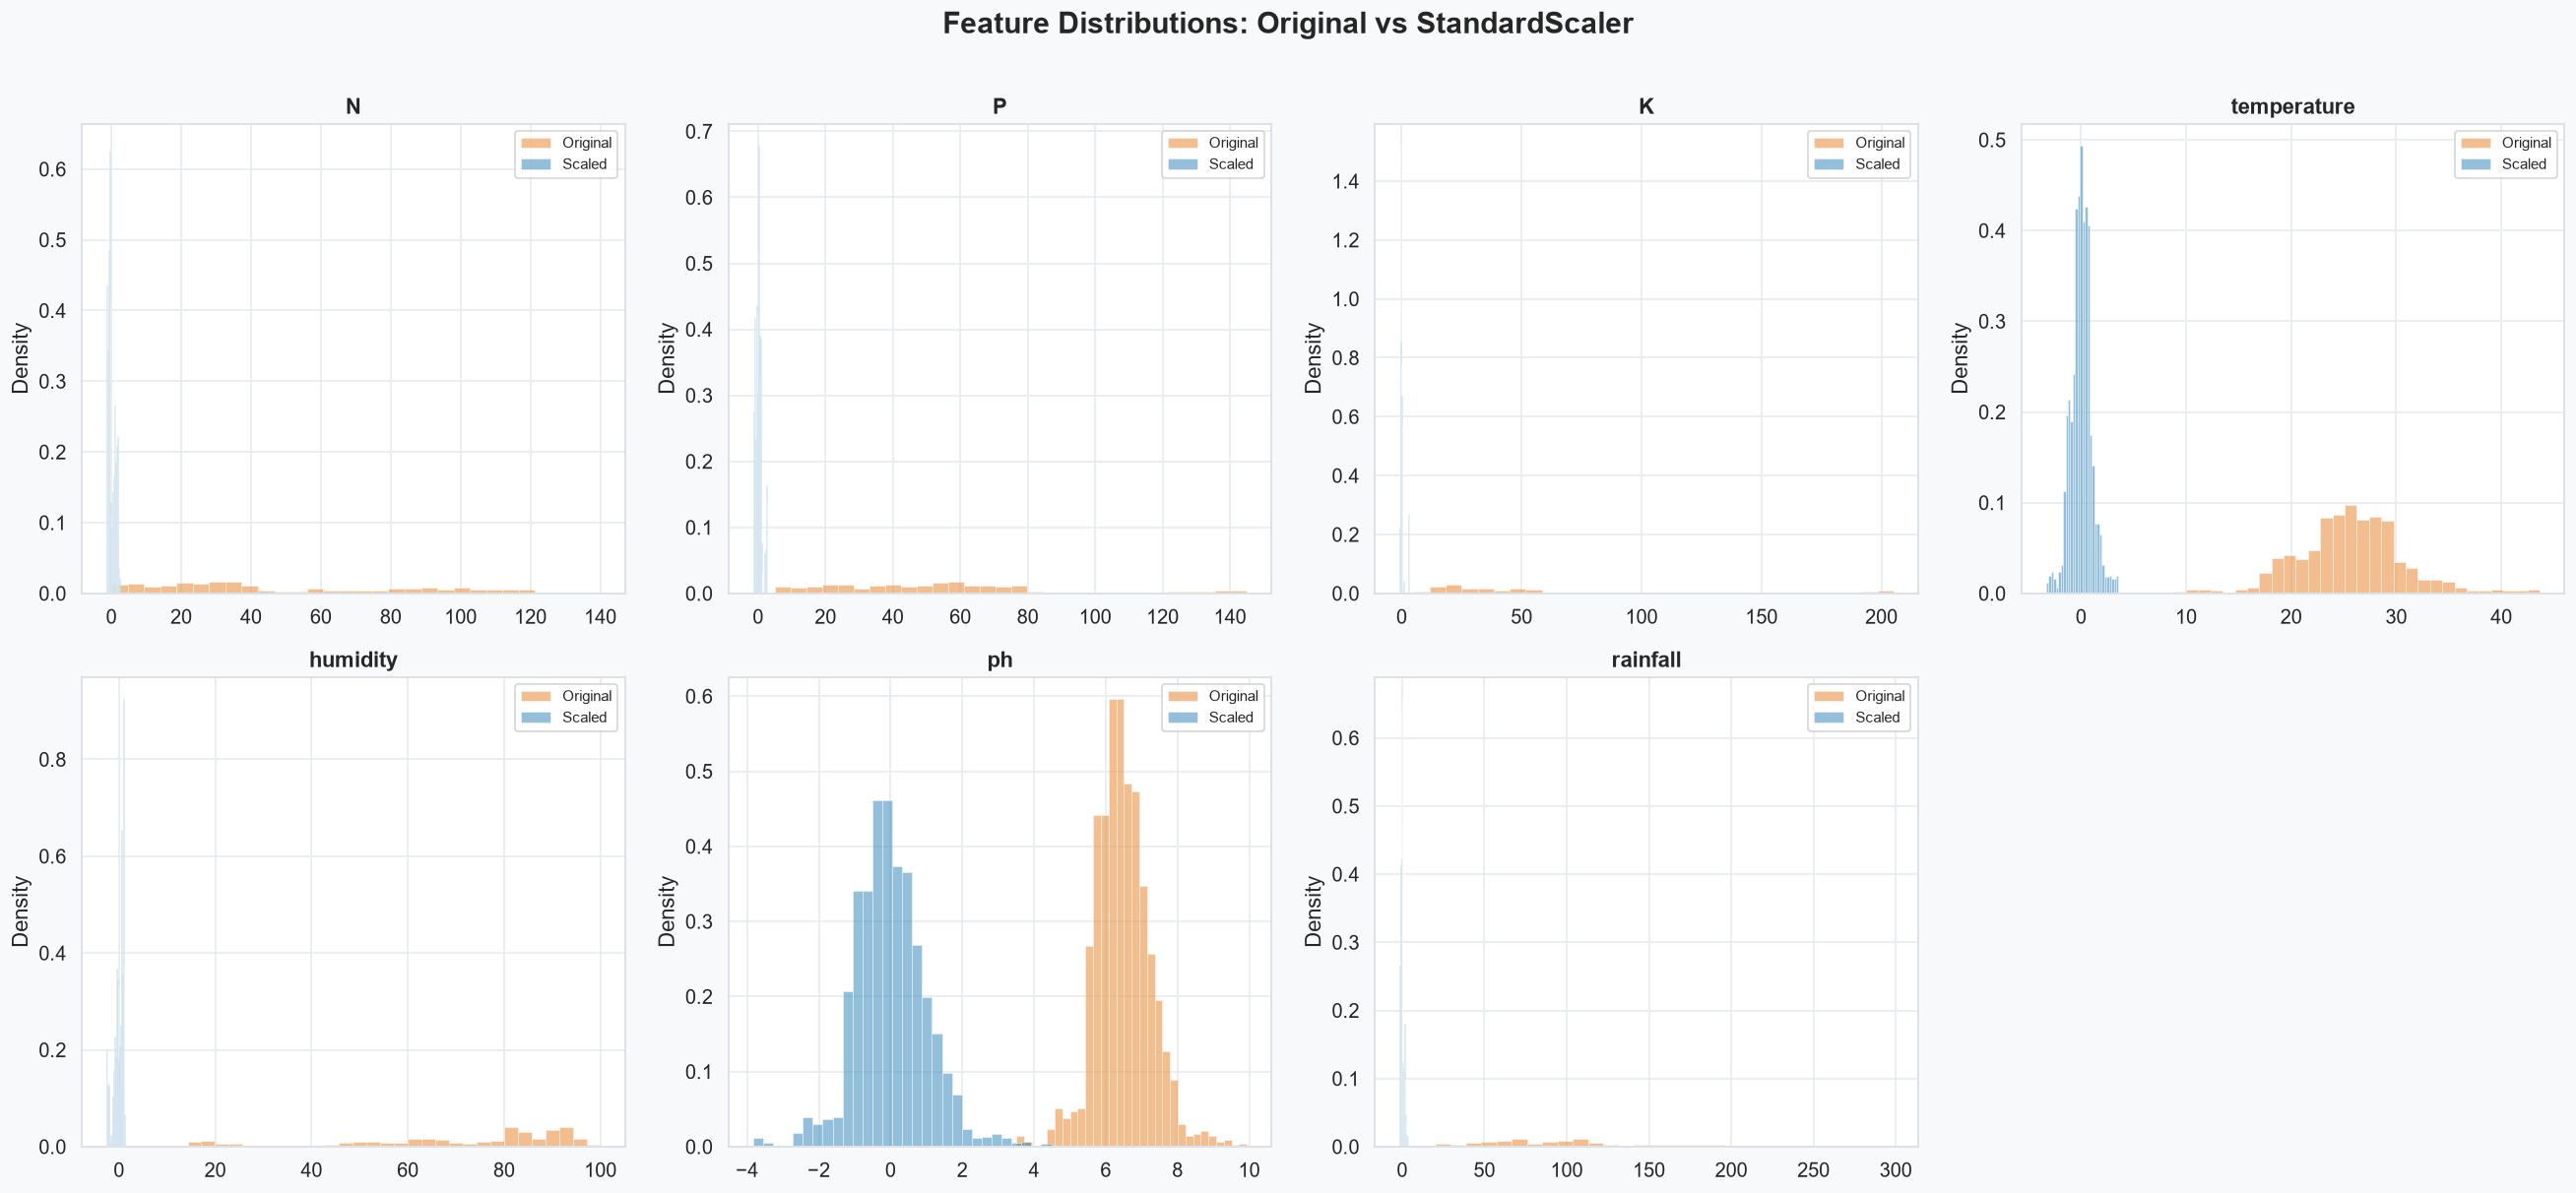

ℹ️  Scaled features retain their original shape but are now centered at 0
   with unit variance, making them comparable across all features.


In [9]:
# Before vs After scaling comparison
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

colors_before = '#e67e22'
colors_after = '#2980b9'

for i, col in enumerate(feature_cols):
    ax = axes[i]
    # Original distribution
    ax.hist(X[col], bins=30, alpha=0.5, color=colors_before, 
            label='Original', edgecolor='white', linewidth=0.5, density=True)
    # Scaled distribution
    ax.hist(X_scaled[col], bins=30, alpha=0.5, color=colors_after, 
            label='Scaled', edgecolor='white', linewidth=0.5, density=True)
    
    ax.set_title(f'{col}', fontweight='bold', fontsize=13)
    ax.legend(fontsize=9)
    ax.set_ylabel('Density')

# Hide unused subplot
axes[-1].set_visible(False)

plt.suptitle('Feature Distributions: Original vs StandardScaler', 
             fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('\u2139\ufe0f  Scaled features retain their original shape but are now centered at 0')
print('   with unit variance, making them comparable across all features.')

## 8. Save Preprocessing Pipeline & Data Splits

Persist the fitted scaler, label encoder, and train/test data for reproducible use in the modeling phase.

In [10]:
# Save train/test splits as CSV
X_train_df = pd.DataFrame(X_train, columns=feature_cols)
X_test_df = pd.DataFrame(X_test, columns=feature_cols)
y_train_df = pd.DataFrame(y_train, columns=['label_encoded'])
y_test_df = pd.DataFrame(y_test, columns=['label_encoded'])

# Add readable crop names alongside encoded labels
y_train_df['crop_name'] = label_encoder.inverse_transform(y_train)
y_test_df['crop_name'] = label_encoder.inverse_transform(y_test)

X_train_df.to_csv('X_train.csv', index=False)
X_test_df.to_csv('X_test.csv', index=False)
y_train_df.to_csv('y_train.csv', index=False)
y_test_df.to_csv('y_test.csv', index=False)

print('\u2705 Train/test CSV files saved:')
print(f'   X_train.csv  ({X_train_df.shape[0]} rows \u00d7 {X_train_df.shape[1]} cols)')
print(f'   X_test.csv   ({X_test_df.shape[0]} rows \u00d7 {X_test_df.shape[1]} cols)')
print(f'   y_train.csv  ({y_train_df.shape[0]} rows)')
print(f'   y_test.csv   ({y_test_df.shape[0]} rows)')

✅ Train/test CSV files saved:
   X_train.csv  (1760 rows × 7 cols)
   X_test.csv   (440 rows × 7 cols)
   y_train.csv  (1760 rows)
   y_test.csv   (440 rows)


In [11]:
# Save the preprocessing pipeline (scaler + label encoder) as a single joblib file
pipeline_artifacts = {
    'scaler': scaler,
    'label_encoder': label_encoder,
    'feature_cols': feature_cols,
    'scaler_type': 'StandardScaler',
    'test_size': TEST_SIZE,
    'random_state': RANDOM_STATE,
    'n_classes': len(label_mapping),
    'label_mapping': label_mapping,
}

joblib.dump(pipeline_artifacts, 'preprocessing_pipeline.joblib')

print('\u2705 Preprocessing pipeline saved to: preprocessing_pipeline.joblib')
print(f'\n   Contents:')
for key, val in pipeline_artifacts.items():
    if isinstance(val, dict):
        print(f'     {key}: dict with {len(val)} entries')
    elif isinstance(val, list):
        print(f'     {key}: {val}')
    else:
        print(f'     {key}: {val}')

# Verify: reload and test
loaded = joblib.load('preprocessing_pipeline.joblib')
assert np.allclose(loaded['scaler'].mean_, scaler.mean_), 'Scaler mismatch!'
print(f'\n\u2705 Pipeline reload test passed.')

✅ Preprocessing pipeline saved to: preprocessing_pipeline.joblib

   Contents:
     scaler: StandardScaler()
     label_encoder: LabelEncoder()
     feature_cols: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
     scaler_type: StandardScaler
     test_size: 0.2
     random_state: 42
     n_classes: 22
     label_mapping: dict with 22 entries

✅ Pipeline reload test passed.


## 9. Summary

### Pipeline Overview

```
Raw Data → Deduplication → Feature–Target Split → Label Encoding → StandardScaler → Stratified 80/20 Split
```

### What was done

| Step | Detail |
|---|---|
| **Target Encoding** | LabelEncoder mapped 22 crop names → integers 0–21 |
| **Feature Scaling** | StandardScaler (z-score normalization): mean=0, std=1 for all 7 features |
| **Train/Test Split** | 80/20 stratified split (random_state=42) ensuring proportional class representation |
| **Artifacts Saved** | `X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv`, `preprocessing_pipeline.joblib`, `label_encoding_map.csv` |

### Design Decisions

1. **StandardScaler over MinMaxScaler** — More robust to the legitimate outliers identified in Phase 2; better suited for the roughly Gaussian distributions of temperature and pH.
2. **80/20 split** — Optimal balance between training data sufficiency (~80 samples/class) and test reliability (~20 samples/class) for a 22-class problem.
3. **Stratification** — Guarantees identical class proportions in train and test, critical for fair evaluation of per-class metrics.
4. **Pipeline persistence** — The fitted scaler and encoder are saved in `preprocessing_pipeline.joblib` so the same transformations can be applied to new/unseen data without refitting.

### Insights & Next Steps
- The preprocessing pipeline is **fully reproducible** — loading `preprocessing_pipeline.joblib` and applying `scaler.transform()` to new data will produce identical scaling.
- **Proceed to Phase 4:** Model training and evaluation using the saved train/test splits.